# Resting EEG, hormonal contraception and self-reported cycle phase

Does a single resting EEG session separate women by hormonal state, and how large would a difference have to be to be seen?

**Data.** OpenNeuro ds007615 (Normannseth, Andersson and Hatlestad-Hall, [doi:10.18112/openneuro.ds007615.v1.0.0](https://doi.org/10.18112/openneuro.ds007615.v1.0.0), CC0; collected for Normannseth et al. 2025, *Frontiers in Human Neuroscience* 19:1647425): 69 healthy women aged 19 to 40, one session each, 64-channel BioSemi EEG at 2048 Hz, four minutes with eyes closed and four minutes with eyes open. A questionnaire gives hormonal contraceptive use (37 current users, 21 past users, 11 never users), contraceptive type, usual cycle length and the self-reported day of the cycle on the day of recording. The dataset also provides a phase label (follicular, ovulatory, luteal) derived from the cycle day. No hormone was measured. Download with `python download_cycle_data.py eeg` or set `DS007615` to the dataset folder.

1. **Spectral measures.** Posterior alpha power, beta power, individual alpha peak frequency, alpha reactivity (eyes closed against eyes open) and the aperiodic exponent of the spectrum.
2. **Contraceptive users against non-users** (past and never users), adjusted for age.
3. **Self-reported phase** among non-users, and how the phase label changes with the counting rule.
4. **Detectable effect size** for each comparison at this sample size.

Spectra for each recording are cached in `results/eeg/`, so the notebook only processes new recordings when it is run again.

In [1]:
import os, json, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt, resample_poly
from scipy import stats
import statsmodels.formula.api as smf
from IPython.display import Image, display
import warnings
warnings.filterwarnings("ignore")
%matplotlib inline

REPO_DIR = Path.cwd()  # run the notebook from the repository folder
DS = Path(os.environ.get("DS007615", "data/ds007615"))
FIG_DIR, RES_DIR = REPO_DIR / "figures", REPO_DIR / "results"
CACHE_DIR = RES_DIR / "eeg"
for d in (FIG_DIR, CACHE_DIR):
    d.mkdir(parents=True, exist_ok=True)

FS_RAW, FS = 2048, 256
EPOCH_S = 2.0
N_EEG = 64
BANDS = {"theta": (4, 8), "alpha": (8, 13), "beta": (13, 30)}
TOTAL = (1, 40)
POSTERIOR = ["P3", "Pz", "P4", "PO3", "POz", "PO4", "PO7", "PO8", "O1", "Oz", "O2"]
FRONTAL = ["F3", "Fz", "F4", "AF3", "AFz", "AF4", "FC1", "FCz", "FC2"]
APERIODIC_FIT = (2, 40)        # Hz, alpha band excluded from the fit
CACHE_VERSION = 1
SEED = 7

BLUE, ORANGE, INK, INK2, MUTED, GRIDLINE = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#8c8b86", "#e4e3de"


def setup():
    import logging
    from matplotlib import font_manager as fm
    logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
    avail = {f.name for f in fm.fontManager.ttflist}
    fam = next((f for f in ["Calibri", "Carlito", "Segoe UI", "Arial"] if f in avail), "DejaVu Sans")
    plt.rcParams.update({
        "font.family": fam, "font.size": 9, "axes.edgecolor": MUTED, "axes.labelcolor": INK2,
        "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
        "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRIDLINE, "grid.linewidth": 0.6,
        "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False, "legend.fontsize": 8,
        "lines.linewidth": 1.6, "figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight",
        "figure.facecolor": "white", "axes.facecolor": "white"})


def save(fig, name):
    path = FIG_DIR / name
    fig.savefig(path)
    plt.close(fig)
    display(Image(filename=str(path), width=900))
    print("saved", path.relative_to(REPO_DIR))


setup()

## Participants and questionnaire

Non-users are past and never users of hormonal contraception. The cycle day and phase are self-reported on the day of recording; the phase label comes with the dataset.

In [2]:
part = pd.read_csv(DS / "participants.tsv", sep="\t")
hc = pd.read_csv(DS / "phenotype" / "hc_usage.tsv", sep="\t")
P = part.merge(hc, on="participant_id", how="left")
P["hc_user"] = P["group"] == 1
P["hc_type"] = np.where(~P["hc_user"], "non-user", np.where(P["main_prev"] == 2, "combined", "progestin-only"))
print(f"{len(P)} women, age {P.age.min()} to {P.age.max()} (median {P.age.median():.0f})")
print(P.groupby("group").size().rename({1: "current user", 2: "past user", 3: "never user"}).to_dict())
print(P.hc_type.value_counts().to_dict())
print(f"non-users with a cycle day: {int(P.loc[~P.hc_user, 'cycle_phase'].notna().sum())} of {int((~P.hc_user).sum())}; "
      f"with a phase label: {int(P.loc[~P.hc_user, 'mens_phase'].notna().sum())}")
print(f"current users with a phase label: {int(P.loc[P.hc_user, 'mens_phase'].notna().sum())} of {int(P.hc_user.sum())}")

69 women, age 19 to 40 (median 25)
{'current user': 37, 'past user': 21, 'never user': 11}
{'non-user': 32, 'progestin-only': 21, 'combined': 16}
non-users with a cycle day: 30 of 32; with a phase label: 27
current users with a phase label: 23 of 37


## Spectra

Each recording is cut to the marked rest period, downsampled to 256 Hz, high-pass filtered at 1 Hz (zero phase) and re-referenced to the average of the good channels. Eye movements and blinks are removed by regressing each channel on the vertical and horizontal electro-oculogram. Channels whose amplitude is far from the others (robust z of log standard deviation above 3, more than three times or less than a fifth of the median), or that exceed 200 µV peak to peak in more than 30% of epochs, are marked bad. The power spectrum is the average of periodograms of 2 s epochs (Hann window, 0.5 Hz resolution); epochs with a peak-to-peak amplitude above 200 µV, or a variance far from the other epochs (robust z above 3.5), are left out.

In [3]:
def read_vhdr(path):
    txt = path.read_text(encoding="utf-8", errors="replace")
    names = re.findall(r"^Ch\d+=([^,]*),", txt, flags=re.M)
    res = [float(r) for r in re.findall(r"^Ch\d+=[^,]*,[^,]*,([^,]*),", txt, flags=re.M)]
    assert "IEEE_FLOAT_32" in txt and "MULTIPLEXED" in txt
    return names, np.array(res)


def robust_z(v):
    med = np.median(v)
    return (v - med) / (1.4826 * np.median(np.abs(v - med)) + 1e-12)


def spectra(sub, acq):
    """Power spectral density (µV²/Hz) of each EEG channel for one recording, with quality counts."""
    base = DS / sub / "eeg" / f"{sub}_task-rest_acq-{acq}"
    names, res = read_vhdr(Path(str(base) + "_eeg.vhdr"))
    ev = pd.read_csv(Path(str(base) + "_events.tsv"), sep="\t")
    a = int(ev.loc[ev.trial_type.str.endswith("_start"), "sample"].iloc[0])
    b = int(ev.loc[ev.trial_type.str.endswith("_end"), "sample"].iloc[0])
    raw = np.fromfile(Path(str(base) + "_eeg.eeg"), dtype="<f4").reshape(-1, len(names))[a:b]
    raw = raw.astype(np.float64) * res
    raw = resample_poly(raw - raw.mean(0), 1, FS_RAW // FS, axis=0)
    raw = sosfiltfilt(butter(4, 1.0, "highpass", fs=FS, output="sos"), raw, axis=0)
    ch = {n: i for i, n in enumerate(names)}
    eog = np.stack([raw[:, ch["VOG1"]] - raw[:, ch["VOG2"]], raw[:, ch["HOG1"]] - raw[:, ch["HOG2"]]], 1)
    eog = eog - eog.mean(0)
    sd = raw[:, :N_EEG].std(0)
    bad = (np.abs(robust_z(np.log(sd))) > 3) | (sd > 3 * np.median(sd)) | (sd < 0.2 * np.median(sd))
    n = int(EPOCH_S * FS)
    for _ in range(3):
        x = raw[:, :N_EEG] - raw[:, :N_EEG][:, ~bad].mean(1, keepdims=True)
        x = x - eog @ np.linalg.lstsq(eog, x, rcond=None)[0]      # remove eye movements and blinks by regression
        ep = x[: (len(x) // n) * n].reshape(-1, n, N_EEG)
        over = (np.ptp(ep, axis=1) > 200).mean(0)                    # share of epochs above 200 µV, per channel
        new = (over > 0.3) & ~bad
        if not new.any():
            break
        bad |= new
    ptp = np.ptp(ep[:, :, ~bad], axis=1).max(1)
    ev_lv = np.log(ep[:, :, ~bad].var(1).mean(1))
    keep = (ptp < 200) & (np.abs(robust_z(ev_lv)) < 3.5)
    w = np.hanning(n)
    X = np.fft.rfft((ep[keep] - ep[keep].mean(1, keepdims=True)) * w[None, :, None], axis=1)
    psd = (np.abs(X) ** 2).mean(0) * 2 / (FS * (w ** 2).sum())
    f = np.fft.rfftfreq(n, 1 / FS)
    sel = f <= 45
    return dict(f=f[sel], psd=psd[sel].T, names=names[:N_EEG], bad=np.array(names[:N_EEG])[bad].tolist(),
                epochs=int(len(ep)), kept=int(keep.sum()))


def cached_spectra(sub):
    path = CACHE_DIR / f"{sub}.npz"
    if path.exists():
        z = np.load(path, allow_pickle=True)
        if int(z["version"]) == CACHE_VERSION:
            return {acq: dict(f=z["f"], psd=z[f"psd_{acq}"], names=z["names"].tolist(), bad=z[f"bad_{acq}"].tolist(),
                              epochs=int(z[f"epochs_{acq}"]), kept=int(z[f"kept_{acq}"])) for acq in ("ec", "eo")}
    out = {acq: spectra(sub, acq) for acq in ("ec", "eo")}
    np.savez_compressed(path, version=CACHE_VERSION, f=out["ec"]["f"], names=np.array(out["ec"]["names"]),
                        **{f"{k}_{acq}": (np.array(v) if k == "bad" else v) for acq in out for k, v in out[acq].items()
                           if k in ("psd", "bad", "epochs", "kept")})
    return out

## Check: recording quality

Epochs kept and channels marked bad in each of the 138 recordings.

In [4]:
SUBJECTS = sorted(P.participant_id)
S = {}
for sub in SUBJECTS:
    S[sub] = cached_spectra(sub)
Q = pd.DataFrame([dict(participant_id=s, acq=a, bad=len(S[s][a]["bad"]), kept=S[s][a]["kept"], epochs=S[s][a]["epochs"])
                  for s in SUBJECTS for a in ("ec", "eo")])
print(f"{len(SUBJECTS)} women, {len(Q)} recordings")
print(f"epochs kept per recording: median {Q.kept.median():.0f} of {Q.epochs.median():.0f} (minimum {Q.kept.min()}); "
      f"bad channels per recording: median {Q.bad.median():g}, maximum {Q.bad.max()}")

69 women, 138 recordings
epochs kept per recording: median 116 of 120 (minimum 71); bad channels per recording: median 2.5, maximum 11


## Measures

All measures use the average spectrum of the posterior channels (P3, Pz, P4, PO3, POz, PO4, PO7, PO8, O1, Oz, O2), except frontal alpha.

- **Alpha and beta power:** absolute power (log10 µV²) and relative power (share of 1 to 40 Hz) in 8 to 13 Hz and 13 to 30 Hz.
- **Aperiodic exponent:** minus the slope of a straight line fitted to log power against log frequency from 2 to 40 Hz, leaving out 7 to 14 Hz.
- **Alpha peak frequency:** centre of gravity, in 7 to 14 Hz, of the power above that line (eyes closed).
- **Alpha reactivity:** log10 of eyes-closed over eyes-open alpha power.

In [5]:
F = S[SUBJECTS[0]]["ec"]["f"]
DF = F[1] - F[0]


def roi(spec, chans):
    idx = [i for i, n in enumerate(spec["names"]) if n in chans and n not in spec["bad"]]
    return spec["psd"][idx].mean(0)


def band(p, lo, hi):
    m = (F >= lo) & (F < hi)
    return p[m].sum() * DF


def aperiodic(p):
    m = (F >= APERIODIC_FIT[0]) & (F <= APERIODIC_FIT[1]) & ~((F >= 7) & (F <= 14))
    slope, icpt = np.polyfit(np.log10(F[m]), np.log10(p[m]), 1)
    return -slope, 10 ** (icpt + slope * np.log10(np.maximum(F, 0.25)))


def measures(sub):
    ec, eo = roi(S[sub]["ec"], POSTERIOR), roi(S[sub]["eo"], POSTERIOR)
    exp_ec, fit = aperiodic(ec)
    m = (F >= 7) & (F <= 14)
    above = np.clip(ec[m] - fit[m], 0, None)
    return dict(participant_id=sub,
                alpha_abs_ec=np.log10(band(ec, *BANDS["alpha"])), alpha_rel_ec=band(ec, *BANDS["alpha"]) / band(ec, *TOTAL),
                beta_rel_ec=band(ec, *BANDS["beta"]) / band(ec, *TOTAL), alpha_rel_eo=band(eo, *BANDS["alpha"]) / band(eo, *TOTAL),
                frontal_alpha_rel_ec=band(roi(S[sub]["ec"], FRONTAL), *BANDS["alpha"]) / band(roi(S[sub]["ec"], FRONTAL), *TOTAL),
                paf_ec=float((F[m] * above).sum() / above.sum()) if above.sum() > 0 else np.nan,
                alpha_peak_above_fit=float(np.log10(ec[m] / fit[m]).max()),
                aperiodic_ec=exp_ec, aperiodic_eo=aperiodic(eo)[0],
                alpha_reactivity=np.log10(band(ec, *BANDS["alpha"]) / band(eo, *BANDS["alpha"])))


M = pd.DataFrame([measures(s) for s in SUBJECTS]).merge(P, on="participant_id")
print(M[["alpha_abs_ec", "alpha_rel_ec", "beta_rel_ec", "paf_ec", "aperiodic_ec", "alpha_reactivity"]].describe().round(3).to_string())
print(f"\nclear alpha peak (at least 26% above the aperiodic line) in {int((M.alpha_peak_above_fit > 0.1).sum())} of {len(M)} women")

       alpha_abs_ec  alpha_rel_ec  beta_rel_ec  paf_ec  aperiodic_ec  alpha_reactivity
count        69.000        69.000       69.000  69.000        69.000            69.000
mean          1.677         0.564        0.162  10.366         1.314             0.633
std           0.467         0.170        0.089   0.755         0.292             0.283
min           0.520         0.140        0.041   8.753         0.382             0.061
25%           1.374         0.446        0.102   9.808         1.105             0.456
50%           1.648         0.591        0.142  10.364         1.369             0.605
75%           2.033         0.698        0.202  10.896         1.485             0.848
max           2.545         0.878        0.460  12.290         2.163             1.307

clear alpha peak (at least 26% above the aperiodic line) in 69 of 69 women


## Contraceptive users against non-users

Each measure is regressed on contraceptive use and age (ordinary least squares). The difference is given in units of the residual standard deviation, which is close to Cohen's d, with its 95% confidence interval. Relative alpha and alpha peak frequency with eyes closed are the two primary measures; p values are corrected over all seven measures (Holm). The same models are repeated with combined and progestin-only users as separate groups, and without the four women who reported hormonal treatment for a medical condition.

In [6]:
from statsmodels.stats.multitest import multipletests

MEASURES = {
    "alpha_rel_ec": "Relative alpha, eyes closed",
    "paf_ec": "Alpha peak frequency (Hz)",
    "alpha_abs_ec": "Absolute alpha (log10 µV²)",
    "beta_rel_ec": "Relative beta, eyes closed",
    "aperiodic_ec": "Aperiodic exponent",
    "alpha_reactivity": "Alpha reactivity (log10 EC/EO)",
    "frontal_alpha_rel_ec": "Frontal relative alpha",
}
PRIMARY = ["alpha_rel_ec", "paf_ec"]
M["age_c"] = M.age - M.age.mean()
M["user"] = M.hc_user.astype(int)


def group_model(data, y, term="user", formula="{y} ~ user + age_c"):
    fit = smf.ols(formula.format(y=y), data=data).fit()
    sd = np.sqrt(fit.mse_resid)
    lo, hi = fit.conf_int().loc[term]
    return dict(measure=y, n=int(fit.nobs), diff=fit.params[term], d=fit.params[term] / sd,
                d_lo=lo / sd, d_hi=hi / sd, p=fit.pvalues[term])


def table(rows):
    T = pd.DataFrame(rows)
    T["p_holm"] = multipletests(T.p, method="holm")[1]
    return T


H = table([group_model(M, y) for y in MEASURES])
H["label"] = H.measure.map(MEASURES)
means = M.groupby("hc_user")[list(MEASURES)].mean().T.rename(columns={False: "non-users", True: "users"})
print(f"users n = {int(M.hc_user.sum())}, non-users n = {int((~M.hc_user).sum())}")
print(H.set_index("label")[["diff", "d", "d_lo", "d_hi", "p", "p_holm"]].join(means.set_index(H.set_index("measure").index.map(MEASURES)))
      .round(3).to_string())

typ = []
for kind in ("combined", "progestin-only"):
    sub = M[M.hc_type.isin([kind, "non-user"])].assign(user=lambda d: (d.hc_type == kind).astype(int))
    typ.append(table([group_model(sub, y) for y in MEASURES]).assign(type=kind))
TYP = pd.concat(typ)
print("\nby contraceptive type, against non-users (Holm within each type):")
print(TYP.assign(label=TYP.measure.map(MEASURES)).pivot(index="label", columns="type", values=["d", "p_holm"]).round(2).to_string())

no_treat = M[M.horm_treatment != 1]
SENS = table([group_model(no_treat, y) for y in MEASURES])
print(f"\nwithout hormonal treatment (n = {len(no_treat)}): "
      + ", ".join(f"{MEASURES[r.measure].split(' (')[0].lower()} d = {r.d:.2f}" for r in SENS.itertuples() if r.measure in PRIMARY))

users n = 37, non-users n = 32
                                 diff      d   d_lo   d_hi      p  p_holm  non-users   users
label                                                                                       
Relative alpha, eyes closed     0.057  0.335 -0.148  0.817  0.171   0.862      0.534   0.589
Alpha peak frequency (Hz)      -0.270 -0.358 -0.841  0.125  0.144   0.862     10.511  10.241
Absolute alpha (log10 µV²)      0.221  0.480 -0.003  0.962  0.052   0.361      1.560   1.778
Relative beta, eyes closed     -0.013 -0.149 -0.632  0.334  0.540   1.000      0.169   0.156
Aperiodic exponent              0.012  0.040 -0.442  0.523  0.868   1.000      1.304   1.322
Alpha reactivity (log10 EC/EO) -0.026 -0.091 -0.573  0.392  0.709   1.000      0.648   0.620
Frontal relative alpha          0.058  0.339 -0.144  0.822  0.165   0.862      0.383   0.439



by contraceptive type, against non-users (Holm within each type):
                                      d                  p_holm               
type                           combined progestin-only combined progestin-only
label                                                                         
Absolute alpha (log10 µV²)         0.63           0.38     0.33            1.0
Alpha peak frequency (Hz)         -0.35          -0.34     1.00            1.0
Alpha reactivity (log10 EC/EO)    -0.07          -0.15     1.00            1.0
Aperiodic exponent                -0.34           0.33     1.00            1.0
Frontal relative alpha             0.40           0.29     0.99            1.0
Relative alpha, eyes closed        0.45           0.22     0.88            1.0
Relative beta, eyes closed        -0.31          -0.02     1.00            1.0



without hormonal treatment (n = 65): relative alpha, eyes closed d = 0.36, alpha peak frequency d = -0.34


## Self-reported phase and the counting rule

The phase label in the dataset follows the cycle day alone: days 1 to 6 are labelled follicular, days 7 to 12 ovulatory and days 14 to 29 luteal, whatever the usual cycle length (no woman reported day 13). In the binary label shipped with the dataset, the ovulatory days are grouped with the luteal days.

A second label is computed by counting back from the next expected menstruation, which uses the usual cycle length: expected ovulation O = cycle length − 14, ovulatory window O − 2 to O + 1, follicular before and luteal after. This rule is also an estimate, since the luteal phase is not always 14 days, but it shows how much the label depends on the rule. Only non-users are used, since a contraceptive cycle has no ovulation.

In [7]:
NU = M[~M.hc_user].copy()
LABELS = {1: "follicular", 2: "ovulatory", 3: "luteal"}
NU["phase_dataset"] = NU.mens_phase.map(LABELS)


def backward_phase(day, length):
    if np.isnan(day) or np.isnan(length):
        return None
    o = length - 14
    return "follicular" if day < o - 2 else ("ovulatory" if day <= o + 1 else "luteal")


NU["phase_backward"] = [backward_phase(d, l) for d, l in zip(NU.cycle_phase, NU.cycle_length)]
day_rule = M.dropna(subset=["mens_phase"]).groupby("mens_phase").cycle_phase.agg(["min", "max", "count"])
print("dataset label against cycle day, all women:\n", day_rule.rename(index=LABELS).to_string())
print("\nthree-phase label against the binary label (1 = first half, 2 = second half):")
print(pd.crosstab(M.mens_phase.map(LABELS), M.mens_phase_bin).to_string())
both = NU.dropna(subset=["phase_dataset", "phase_backward"])
agree = int((both.phase_dataset == both.phase_backward).sum())
print(f"\nnon-users with a cycle day: {int(NU.cycle_phase.notna().sum())}; with day and cycle length: {int(NU.phase_backward.notna().sum())}; "
      f"with both labels: {len(both)}")
print(pd.crosstab(both.phase_dataset, both.phase_backward, margins=True).to_string())
print(f"same label under both rules: {agree} of {len(both)}")
print(f"cycle length of non-users: median {NU.cycle_length.median():.0f} days, range {NU.cycle_length.min():.0f} to {NU.cycle_length.max():.0f}")

dataset label against cycle day, all women:
              min   max  count
mens_phase                   
follicular   1.0   6.0     14
ovulatory    7.0  12.0     13
luteal      14.0  29.0     23

three-phase label against the binary label (1 = first half, 2 = second half):


mens_phase_bin  1.0  2.0
mens_phase              
follicular       14    0
luteal            0   23
ovulatory         0   13

non-users with a cycle day: 30; with day and cycle length: 29; with both labels: 26
phase_backward  follicular  luteal  ovulatory  All
phase_dataset                                     
follicular               6       0          0    6
luteal                   2       8          4   14
ovulatory                5       1          0    6
All                     13       9          4   26
same label under both rules: 14 of 26
cycle length of non-users: median 28 days, range 22 to 40


Luteal against the other phases, for the two primary measures, under each rule (non-users, adjusted for age). With 27 to 29 women split into two groups, these comparisons can only detect large differences (next section).

In [8]:
PH = []
for rule in ("phase_dataset", "phase_backward"):
    d = NU.dropna(subset=[rule]).assign(luteal=lambda x: (x[rule] == "luteal").astype(int))
    for y in PRIMARY:
        r = group_model(d, y, term="luteal", formula="{y} ~ luteal + age_c")
        PH.append(dict(r, rule=rule.replace("phase_", ""), n_luteal=int(d.luteal.sum()), n_other=int((1 - d.luteal).sum())))
PH = pd.DataFrame(PH)
print(PH[["rule", "measure", "n_luteal", "n_other", "diff", "d", "d_lo", "d_hi", "p"]].round(3).to_string(index=False))

    rule      measure  n_luteal  n_other   diff      d   d_lo  d_hi     p
 dataset alpha_rel_ec        15       12 -0.043 -0.243 -1.059 0.574 0.545
 dataset       paf_ec        15       12  0.326  0.454 -0.363 1.270 0.263
backward alpha_rel_ec        10       19 -0.115 -0.710 -1.535 0.115 0.089
backward       paf_ec        10       19  0.197  0.239 -0.585 1.064 0.556


## Detectable effect size

Smallest standardised difference that a two-sided test at α = 0.05 would detect with 80% power. Between women, it depends on the group sizes. In a within-woman design, with each woman recorded in two phases, it also depends on how stable the measure is between sessions; the curve uses an **assumed** test-retest correlation of 0.8, as an illustration, and expresses the effect in the same between-women units.

In [9]:
from scipy.optimize import brentq

RHO = 0.8
n_grid = np.arange(8, 121)


def power(d, df, k):
    """Power of a two-sided t test at alpha 0.05, noncentrality d * k."""
    c = stats.t.ppf(0.975, df)
    return stats.nct.sf(c, df, d * k) + np.nan_to_num(stats.nct.cdf(-c, df, d * k))


def mde_two(n1, n2):
    return brentq(lambda d: power(d, n1 + n2 - 2, np.sqrt(n1 * n2 / (n1 + n2))) - 0.8, 0.01, 3)


def mde_paired(n):
    return brentq(lambda d: power(d, n - 1, np.sqrt(n)) - 0.8, 0.01, 3) * np.sqrt(2 * (1 - RHO))


mde_between = np.array([mde_two(n, n) for n in n_grid])
mde_within = np.array([mde_paired(n) for n in n_grid])
n_users, n_non = int(M.hc_user.sum()), int((~M.hc_user).sum())
ph_ds = PH[(PH.rule == "dataset")].iloc[0]
MDE = {
    "users_vs_nonusers": mde_two(n_users, n_non),
    "luteal_vs_other_nonusers": mde_two(int(ph_ds.n_luteal), int(ph_ds.n_other)),
    "within_same_women_assumed_rho": mde_paired(int(ph_ds.n_luteal + ph_ds.n_other)),
}
for k, v in MDE.items():
    print(f"{k}: d = {v:.2f}")
n_for_05 = int(n_grid[np.argmax(mde_between <= 0.5)])
print(f"women per group for d = 0.5 between groups: {n_for_05}; "
      f"women for d = 0.5 within women (rho {RHO}): {int(n_grid[np.argmax(mde_within <= 0.5)])}")

users_vs_nonusers: d = 0.69
luteal_vs_other_nonusers: d = 1.13
within_same_women_assumed_rho: d = 0.35
women per group for d = 0.5 between groups: 64; women for d = 0.5 within women (rho 0.8): 15


## Figure

**A** Average posterior spectrum with eyes closed, with 95% confidence bands. **B** Difference between contraceptive users and non-users for each measure (primary measures in bold), with 95% confidence intervals; the grey band marks differences smaller than this sample could detect with 80% power. **C** Cycle day and usual cycle length of the non-users, coloured by the phase label in the dataset; the dashed lines are the fixed day limits of that label, and the grey band is the ovulatory window when counting back from the next menstruation. **D** Smallest detectable difference against sample size; the dots mark the two comparisons in this dataset (geometric mean of the two group sizes).

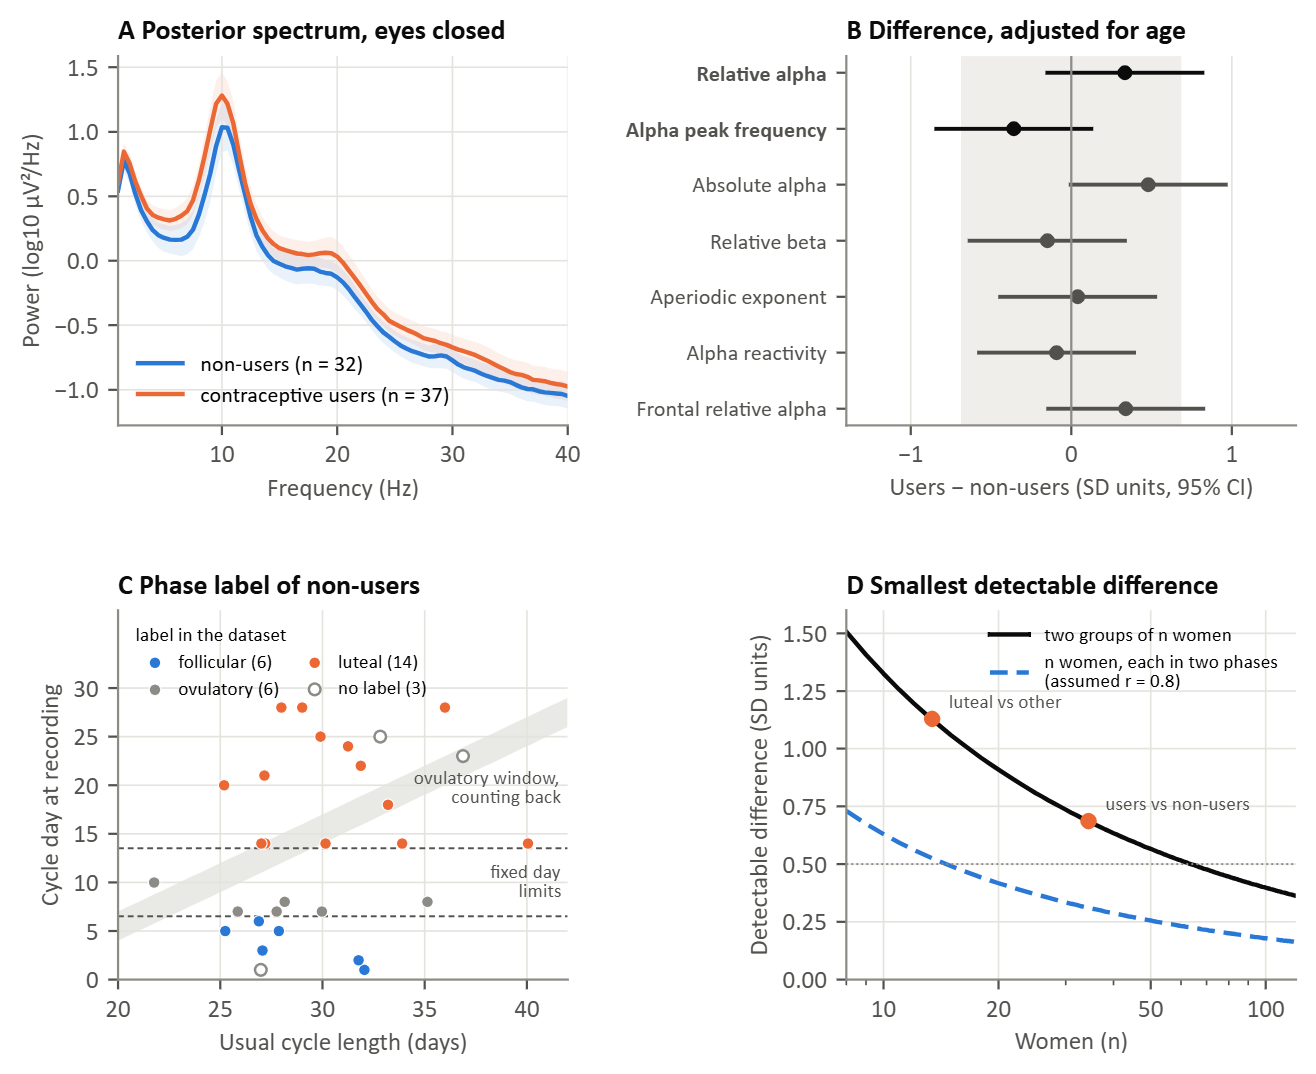

saved figures/eeg_contraception_phase.png


In [10]:
SHORT = {"alpha_rel_ec": "Relative alpha", "paf_ec": "Alpha peak frequency", "alpha_abs_ec": "Absolute alpha",
         "beta_rel_ec": "Relative beta", "aperiodic_ec": "Aperiodic exponent", "alpha_reactivity": "Alpha reactivity",
         "frontal_alpha_rel_ec": "Frontal relative alpha"}
fig, ax = plt.subplots(2, 2, figsize=(7.6, 6.0))
fig.subplots_adjust(hspace=0.5, wspace=0.62)

a = ax[0, 0]
fsel = (F >= 1) & (F <= 40)
for grp, col, lab in ((False, BLUE, f"non-users (n = {n_non})"), (True, ORANGE, f"contraceptive users (n = {n_users})")):
    L = np.log10(np.array([roi(S[s]["ec"], POSTERIOR) for s in M.loc[M.hc_user == grp, "participant_id"]]))[:, fsel]
    mu, se = L.mean(0), L.std(0, ddof=1) / np.sqrt(len(L))
    a.fill_between(F[fsel], mu - 1.96 * se, mu + 1.96 * se, color=col, alpha=0.18, lw=0)
    a.plot(F[fsel], mu, color=col, label=lab)
a.set(xlabel="Frequency (Hz)", ylabel="Power (log10 µV²/Hz)", xlim=(1, 40), title="A  Posterior spectrum, eyes closed")
a.legend(loc="lower left")

a = ax[0, 1]
yy = np.arange(len(H))[::-1]
for y0, r in zip(yy, H.itertuples()):
    col = INK if r.measure in PRIMARY else INK2
    a.plot([r.d_lo, r.d_hi], [y0, y0], color=col, lw=1.4)
    a.plot(r.d, y0, "o", color=col, ms=4.5)
a.axvline(0, color=MUTED, lw=0.8)
a.axvspan(-MDE["users_vs_nonusers"], MDE["users_vs_nonusers"], color=GRIDLINE, alpha=0.6, lw=0)
a.set_yticks(yy, [SHORT[m] for m in H.measure], fontsize=8)
for t, m in zip(a.get_yticklabels(), H.measure):
    t.set_fontweight("bold" if m in PRIMARY else "normal")
a.set(xlabel="Users − non-users (SD units, 95% CI)", xlim=(-1.4, 1.4), title="B  Difference, adjusted for age")
a.grid(axis="y", visible=False)

a = ax[1, 0]
PCOL = {"follicular": BLUE, "ovulatory": MUTED, "luteal": ORANGE}
L_ = np.linspace(20, 42, 50)
a.fill_between(L_, L_ - 16, L_ - 13, color=GRIDLINE, alpha=0.8, lw=0)
a.text(41.7, 21.5, "ovulatory window,\ncounting back", fontsize=7, color=INK2, ha="right", va="top")
a.text(41.7, 10, "fixed day\nlimits", fontsize=7, color=INK2, ha="right", va="center")
jit = pd.Series(np.random.default_rng(SEED).uniform(-0.25, 0.25, len(NU)), index=NU.index)
for ph, col in list(PCOL.items()) + [(None, MUTED)]:
    d = NU[(NU.phase_dataset == ph if ph else NU.phase_dataset.isna()) & NU.cycle_length.notna() & NU.cycle_phase.notna()]
    a.scatter(d.cycle_length + jit[d.index], d.cycle_phase, s=18, zorder=3, label=f"{ph or 'no label'} ({len(d)})",
              color=col if ph else "white", edgecolor="white" if ph else col, lw=0.4 if ph else 0.9)
for y0 in (6.5, 13.5):
    a.axhline(y0, color=INK2, lw=0.7, ls=(0, (3, 2)))
a.set(xlabel="Usual cycle length (days)", ylabel="Cycle day at recording", xlim=(20, 42), ylim=(0, 38),
      yticks=range(0, 31, 5), title="C  Phase label of non-users")
a.legend(title="label in the dataset", loc="upper left", ncol=2, fontsize=7, title_fontsize=7, columnspacing=0.8,
         handletextpad=0.2, alignment="left")

a = ax[1, 1]
a.plot(n_grid, mde_between, color=INK, label="two groups of n women")
a.plot(n_grid, mde_within, color=BLUE, ls=(0, (4, 2)), label=f"n women, each in two phases\n(assumed r = {RHO})")
pts = [(np.sqrt(n_users * n_non), MDE["users_vs_nonusers"], "users vs non-users"),
       (np.sqrt(ph_ds.n_luteal * ph_ds.n_other), MDE["luteal_vs_other_nonusers"], "luteal vs other")]
for x0, y0, lab in pts:
    a.plot(x0, y0, "o", color=ORANGE, ms=5, zorder=3)
    a.annotate(lab, (x0, y0), xytext=(6, 4), textcoords="offset points", fontsize=7, color=INK2)
a.axhline(0.5, color=MUTED, lw=0.7, ls=":")
a.set(xlabel="Women (n)", ylabel="Detectable difference (SD units)", xscale="log",
      ylim=(0, 1.6), xlim=(8, 120), title="D  Smallest detectable difference")
a.set_xticks([10, 20, 50, 100], ["10", "20", "50", "100"])
a.legend(loc="upper right", fontsize=7)
save(fig, "eeg_contraception_phase.png")

## Results file

In [11]:
def clean(v):
    if isinstance(v, (np.floating, float)):
        return None if np.isnan(v) else float(f"{float(v):.4g}")
    if isinstance(v, (np.integer,)):
        return int(v)
    return v


R = {
    "dataset": "OpenNeuro ds007615 v1.0.0",
    "n_women": len(M), "n_users": n_users, "n_nonusers": n_non,
    "users_by_type": M[M.hc_user].hc_type.value_counts().to_dict(),
    "quality": {"epochs_kept_median": clean(Q.kept.median()), "epochs_kept_min": clean(Q.kept.min()),
                "epochs_per_recording": clean(Q.epochs.median()), "bad_channels_median": clean(Q.bad.median()),
                "bad_channels_max": clean(Q.bad.max())},
    "measures_mean_sd": {m: [clean(M[m].mean()), clean(M[m].std())] for m in MEASURES},
    "users_vs_nonusers": [{k: clean(v) for k, v in r.items() if k != "label"} for r in H.to_dict("records")],
    "by_type": [{k: clean(v) for k, v in r.items()} for r in TYP.to_dict("records")],
    "without_hormonal_treatment": [{k: clean(v) for k, v in r.items()} for r in SENS.to_dict("records")],
    "phase_label_rule": {LABELS[int(k)]: [clean(v["min"]), clean(v["max"])] for k, v in day_rule.iterrows()},
    "phase_relabel": {"n_both": len(both), "same_label": agree,
                      "crosstab": {f"{a_}->{b_}": int(((both.phase_dataset == a_) & (both.phase_backward == b_)).sum())
                                   for a_ in LABELS.values() for b_ in LABELS.values()}},
    "luteal_vs_other": [{k: clean(v) for k, v in r.items()} for r in PH.to_dict("records")],
    "mde_d": {k: clean(v) for k, v in MDE.items()}, "assumed_rho": RHO,
}
(RES_DIR / "eeg_contraception_phase.json").write_text(json.dumps(R, indent=1))
print("saved results/eeg_contraception_phase.json")

saved results/eeg_contraception_phase.json
